# Explore burn2scar

burn2scar pairs Sentinel-2 Level-1C images with seven-class burn-scar masks for 13,895 fires mapped by EFFIS in
Italy, Spain, France and Greece, 2020 to 2026: 26,846 tiles of 2.56 × 2.56 km. This notebook looks at the data:
where the fires are, what the masks hold, one fire seen twice, a random gallery, and how each class looks in
the 13 bands.

It downloads only the tiles it shows, a few MB each, from [Hugging Face](https://huggingface.co/datasets/neet1797/burn2scar).
With the [Zenodo release](https://doi.org/10.5281/zenodo.23986827) unzipped, set `BURN2SCAR_ROOT` to its folder
to read from disk instead.

**Contents:** 1. The index · 2. Where the fires are · 3. What the masks hold · 4. One fire, two dates ·
5. A random gallery · 6. How the classes look in the bands · 7. Picking tiles for your own work

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

%config InlineBackend.figure_format = "png"
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.titlesize": 10, "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False})

DATASET = "neet1797/burn2scar"                 # burn2scar 3.0 on Hugging Face
LOCAL_ROOT = os.environ.get("BURN2SCAR_ROOT")  # or a folder holding the unzipped Zenodo release
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools").is_dir())


def fetch(path):
    """A file of the release, from LOCAL_ROOT when it is set, else downloaded once from Hugging Face."""
    if LOCAL_ROOT:
        return Path(LOCAL_ROOT) / path
    from huggingface_hub import hf_hub_download
    return Path(hf_hub_download(DATASET, path, repo_type="dataset"))


BANDS = ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B09", "B10", "B11", "B12"]
# Mask value: (name, colour). Burn age is one hue, darker when more recent, as in the paper's figures.
CLASSES = {2: ("fresh_burn", "#7f2704"), 3: ("old_burn", "#d9480f"), 7: ("older_burn", "#f5a04a"),
           0: ("clear", "#f1efe8"), 6: ("water", "#2a78d6"), 5: ("cloud shadow", "#25272d"),
           4: ("cloud", "#b4c0ce"), 255: ("no data", "#000000")}
_values = sorted(CLASSES)
MASK_CMAP = ListedColormap([CLASSES[v][1] for v in _values])
MASK_NORM = BoundaryNorm([v - .5 for v in _values] + [_values[-1] + .5], MASK_CMAP.N)
COUNTRY = {"IT": "Italy", "ES": "Spain", "FR": "France", "EL": "Greece"}


def read_tile(row):
    """The 13-band image (reflectance x 10,000) and the mask of one row of the index."""
    with rasterio.open(fetch(row["image_path"])) as src:
        image = src.read()
    with rasterio.open(fetch(row["mask_path"])) as src:
        mask = src.read(1)
    return image, mask


def composite(image, recipe):
    """An RGB picture from three bands, each divided by a fixed reflectance so tiles compare with each other."""
    rgb = np.stack([image[BANDS.index(band)] / 10000 / scale for band, scale in recipe], axis=-1)
    return np.clip(rgb, 0, 1) ** .9


TRUE_COLOUR = (("B04", .28), ("B03", .28), ("B02", .32))
FALSE_COLOUR = (("B12", .40), ("B8A", .50), ("B04", .28))  # burned ground shows red-brown, vegetation green


def show_image(ax, image, mask=None, recipe=FALSE_COLOUR, title=None):
    """Draw a tile; with a mask, outline its burn (fresh and old) in white."""
    ax.imshow(composite(image, recipe), interpolation="bilinear")
    if mask is not None and np.isin(mask, [2, 3]).any():
        ax.contour(np.isin(mask, [2, 3]).astype(float), levels=[.5], colors="white", linewidths=.9)
    ax.set_axis_off()
    if title:
        ax.set_title(title)


def show_mask(ax, mask, title=None):
    ax.imshow(mask, cmap=MASK_CMAP, norm=MASK_NORM, interpolation="nearest")
    ax.set_axis_off()
    if title:
        ax.set_title(title)


def class_legend(fig, values=(2, 3, 7, 0, 6, 5, 4), **kwargs):
    handles = [Patch(facecolor=CLASSES[v][1], edgecolor="#8a8984", linewidth=.5, label=CLASSES[v][0]) for v in values]
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False, **kwargs)

## 1. The index

`index.csv` has one row per tile: where its image and mask are, the fire and scene dates, the place, the share
of each class, quality flags and the splits.

In [2]:
index = pd.read_csv(fetch("index.csv"), low_memory=False)
print(f"{len(index):,} tiles from {index['fire_id'].nunique():,} fires, {len(index.columns)} columns")
index[["tile_id", "country", "fire_date", "scene_time", "window", "age_days", "area_ha", "frac_fresh", "frac_old", "split"]].head()

/root/projects/burn2scar/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


26,846 tiles from 13,895 fires, 56 columns


,tile_id,country,fire_date,scene_time,window,age_days,area_ha,frac_fresh,frac_old,split
0,effis_179369/2022-03-22T10-28-13,IT,2022-01-24,2022-03-22T10:28:13,fresh,57.43,49.0,0.074677,0.000000,train
1,effis_179369/2022-10-18T10-28-12,IT,2022-01-24,2022-10-18T10:28:12,old,267.43,49.0,0.000000,0.074677,train
2,effis_179370/2022-02-08T10-38-27,IT,2022-01-19,2022-02-08T10:38:27,fresh,20.41,31.0,0.047440,0.000000,train
3,effis_179370/2022-10-18T10-28-38,IT,2022-01-19,2022-10-18T10:28:38,old,272.40,31.0,0.000000,0.047440,train
4,effis_179376/2022-01-27T10-48-39,FR,2021-12-15,2022-01-27T10:48:39,fresh,43.45,17.0,0.153610,0.061356,test


In [3]:
counts = index.pivot_table(index="country", columns="window", values="tile_id", aggfunc="count")
counts = counts.rename(index=COUNTRY).rename(columns={"fresh": "fresh scenes (5–60 days)", "old": "old scenes (120–300 days)"})
counts.loc["All"] = counts.sum()
counts

window,fresh scenes (5–60 days),old scenes (120–300 days)
country,,
Greece,1051,1008
Spain,2442,2275
France,2388,2317
Italy,8014,7351
All,13895,12951


## 2. Where the fires are

Every tile is centred on its fire. Fires ran from the largest down within each country's share of the download
budget, so Spain and France lost their smallest fires.

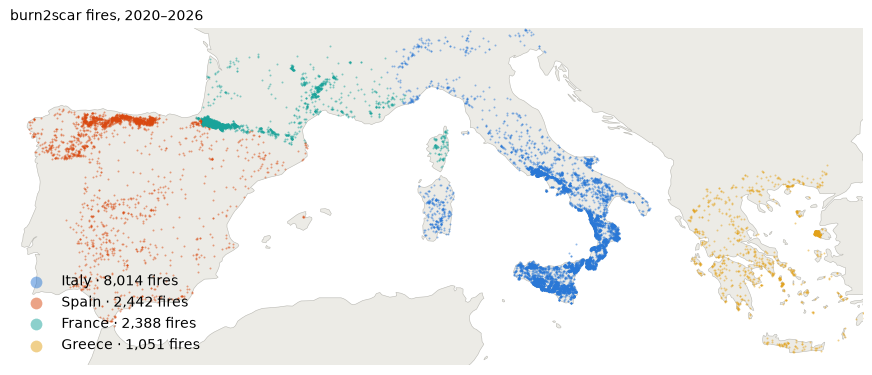

In [4]:
import json

land = json.loads((REPO / "tools" / "data" / "land_med_ne50m.geojson").read_text())
fig, ax = plt.subplots(figsize=(11, 5.2))
for feature in land["features"]:
    polygons = feature["geometry"]["coordinates"]
    for polygon in polygons if feature["geometry"]["type"] == "MultiPolygon" else [polygons]:
        ring = np.asarray(polygon[0])
        ax.fill(ring[:, 0], ring[:, 1], color="#ecebe6", edgecolor="#b9b8b2", linewidth=.4)
colours = {"IT": "#2a78d6", "ES": "#d9480f", "FR": "#1aa39a", "EL": "#e3a21a"}
fires = index.drop_duplicates("fire_id")
for country, colour in colours.items():
    part = fires[fires["country"] == country]
    ax.scatter(part["lon"], part["lat"], s=2, color=colour, alpha=.5, linewidths=0,
               label=f"{COUNTRY[country]} · {len(part):,} fires")
ax.set_xlim(-10, 28)
ax.set_ylim(34.5, 46.5)
ax.set_aspect(1.25)
ax.set_xticks([])
ax.set_yticks([])
for side in ax.spines.values():
    side.set_visible(False)
ax.legend(loc="lower left", markerscale=6, frameon=False)
ax.set_title("burn2scar fires, 2020–2026")
plt.show()

## 3. What the masks hold

Each tile's class shares are in the index, so the composition of the whole data set needs no downloads. Shares
are of valid pixels, without no data.

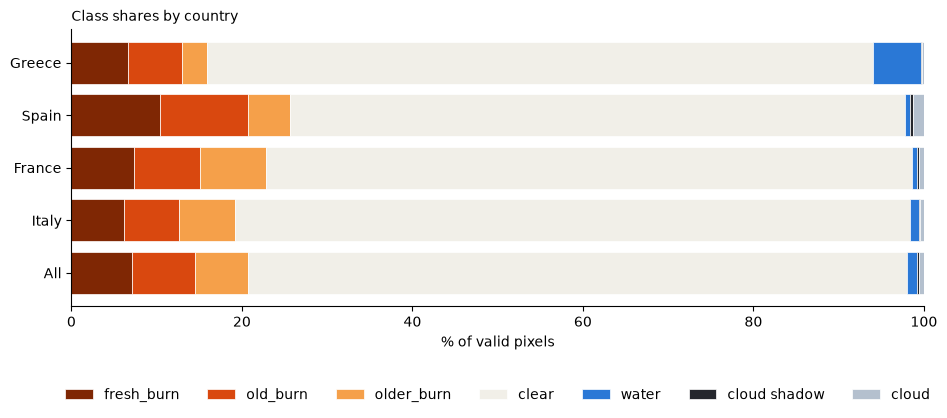

,fresh_burn,old_burn,older_burn,clear,water,cloud shadow,cloud
country,,,,,,,
Greece,6.59,6.33,3.01,78.11,5.63,0.11,0.22
Spain,10.44,10.22,4.98,72.11,0.61,0.36,1.28
France,7.35,7.75,7.72,75.78,0.63,0.16,0.60
Italy,6.18,6.39,6.63,79.15,1.09,0.16,0.40
All,7.16,7.30,6.25,77.24,1.27,0.19,0.58


In [5]:
shares = {"fresh": 2, "old": 3, "older": 7, "clear": 0, "water": 6, "shadow": 5, "cloud": 4}
frac = index[[f"frac_{name}" for name in shares]].div(1 - index["frac_nodata"], axis=0)
frac.columns = [CLASSES[v][0] for v in shares.values()]
by_country = frac.groupby(index["country"]).mean().rename(index=COUNTRY)
by_country.loc["All"] = frac.mean()

fig, ax = plt.subplots(figsize=(11, 3.6))
left = np.zeros(len(by_country))
for name, value in zip(by_country.columns, shares.values()):
    ax.barh(by_country.index, by_country[name] * 100, left=left, color=CLASSES[value][1],
            edgecolor="white", linewidth=.5, label=name)
    left += by_country[name].to_numpy() * 100
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% of valid pixels")
ax.legend(ncol=7, loc="upper center", bbox_to_anchor=(.5, -.25), frameon=False)
ax.set_title("Class shares by country")
plt.show()
(by_country * 100).round(2)

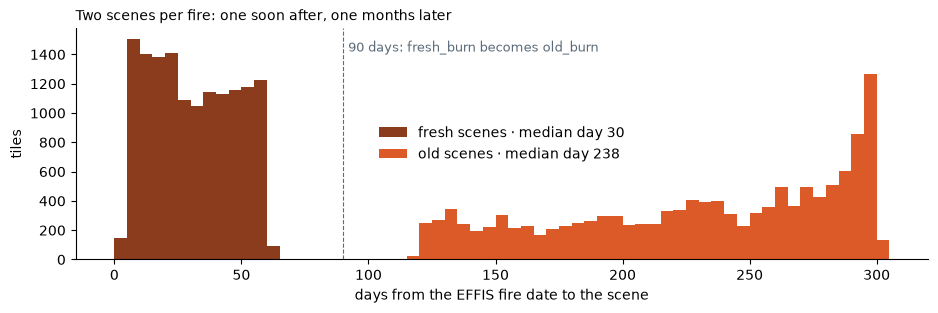

In [6]:
fig, ax = plt.subplots(figsize=(11, 3))
for window, colour in (("fresh", CLASSES[2][1]), ("old", CLASSES[3][1])):
    days = index.loc[index["window"] == window, "age_days"]
    ax.hist(days, bins=np.arange(0, 310, 5), color=colour, alpha=.9, label=f"{window} scenes · median day {days.median():.0f}")
ax.axvline(90, color="#5b6b7a", linewidth=.8, linestyle="--")
ax.text(92, ax.get_ylim()[1] * .9, "90 days: fresh_burn becomes old_burn", color="#5b6b7a", fontsize=9)
ax.set_xlabel("days from the EFFIS fire date to the scene")
ax.set_ylabel("tiles")
ax.legend(frameon=False)
ax.set_title("Two scenes per fire: one soon after, one months later")
plt.show()

## 4. One fire, two dates

A fire from the test set seen twice: a few weeks after it, and months later. False colour shows burned ground in
red-brown and vegetation in green. The white line outlines the burn in the mask.

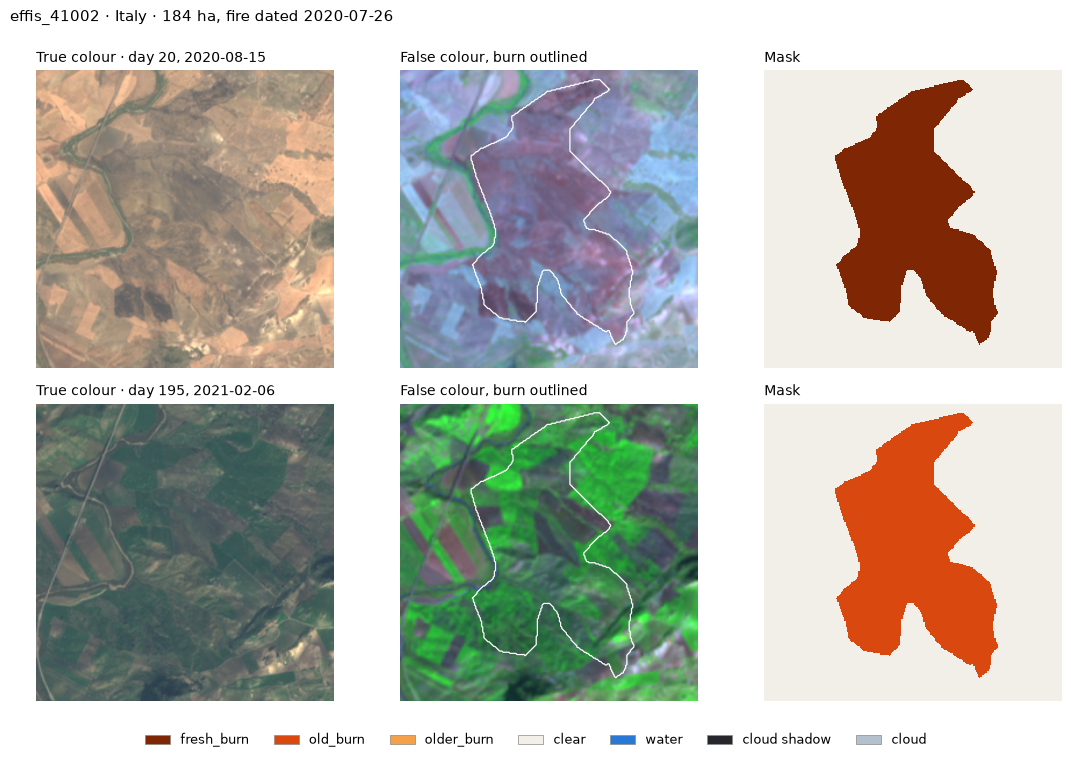

In [7]:
hidden = index["frac_cloud"] + index["frac_shadow"] + index["frac_nodata"]
test = index[(index["split"] == "test") & (hidden < .02)]
fresh_fires = set(test.loc[(test["window"] == "fresh") & (test["frac_fresh"] >= .2), "fire_id"])
old_fires = set(test.loc[(test["window"] == "old") & (test["frac_old"] >= .15), "fire_id"])
fire_id = pd.Series(sorted(fresh_fires & old_fires)).sample(1, random_state=1).iloc[0]
pair = test[test["fire_id"] == fire_id].sort_values("age_days")

fig, axes = plt.subplots(2, 3, figsize=(11, 7.6))
for row_axes, (_, tile) in zip(axes, pair.iterrows()):
    image, mask = read_tile(tile)
    when = f"day {tile['age_days']:.0f}, {str(tile['scene_time'])[:10]}"
    show_image(row_axes[0], image, recipe=TRUE_COLOUR, title=f"True colour · {when}")
    show_image(row_axes[1], image, mask, title="False colour, burn outlined")
    show_mask(row_axes[2], mask, title="Mask")
class_legend(fig, fontsize=9)
fig.suptitle(f"{fire_id} · {COUNTRY[pair.iloc[0]['country']]} · {pair.iloc[0]['area_ha']:.0f} ha, "
             f"fire dated {str(pair.iloc[0]['fire_date'])[:10]}", x=.01, ha="left", fontsize=11)
fig.subplots_adjust(left=.01, right=.99, top=.9, bottom=.07, wspace=.04, hspace=.12)
plt.show()

Months later the same ground is labelled old_burn, whether or not the scar still shows: old_burn records when EFFIS
mapped the fire, and vegetation often grows back within a season. It is kept as its own class so last season's
scars don't count as fresh burn.

## 5. A random gallery

Eight tiles drawn at random, with a fixed seed, from tiles with at least 10 % burn. Change `random_state` for
another eight.

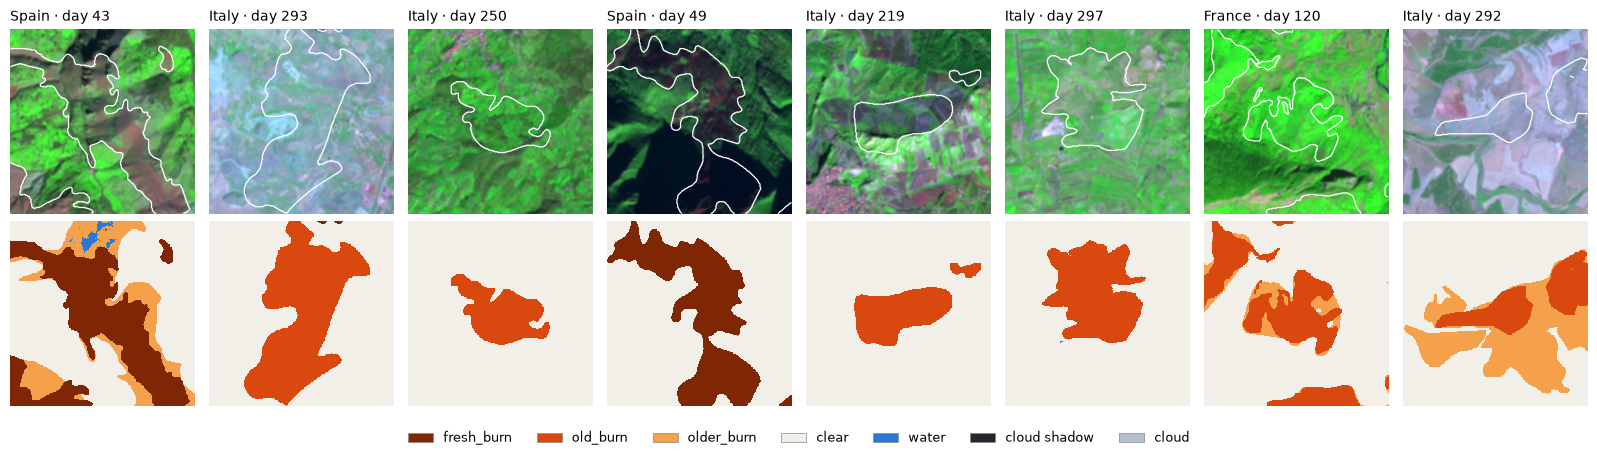

In [8]:
burned = index[(index["frac_fresh"] + index["frac_old"] >= .10) & (index["frac_nodata"] < .02)]
gallery = burned.sample(8, random_state=42)
tiles = [read_tile(row) for _, row in gallery.iterrows()]

fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for column, (_, row), (image, mask) in zip(axes.T, gallery.iterrows(), tiles):
    show_image(column[0], image, mask, title=f"{COUNTRY[row['country']]} · day {row['age_days']:.0f}")
    show_mask(column[1], mask)
class_legend(fig, fontsize=9)
fig.subplots_adjust(left=.005, right=.995, top=.92, bottom=.1, wspace=.04, hspace=.04)
plt.show()

## 6. How the classes look in the bands

The median top-of-atmosphere reflectance of each class over the tiles above. Fresh burn, cloud shadow and water are
all darker than clear ground in the near infrared (B08, B8A), which is why shadow and water can be mistaken for
burn; in the shortwave infrared (B11, B12) fresh burn stays bright while shadow and water stay dark. The data paper
shows the same over thousands of tiles.

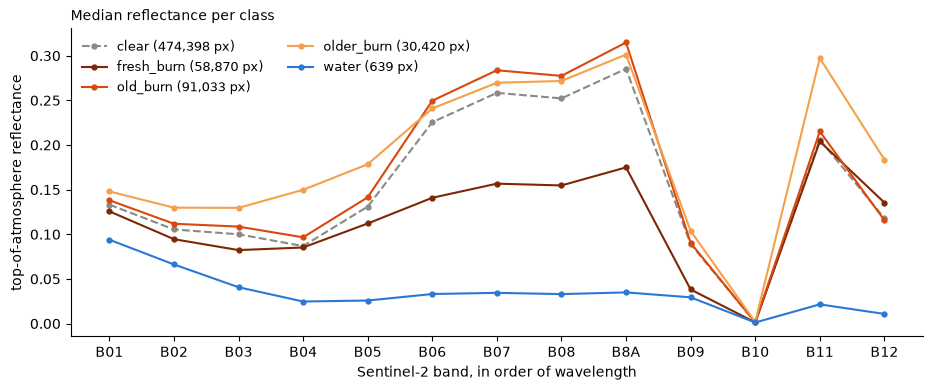

In [9]:
pixels = {value: [] for value in CLASSES if value != 255}
for image, mask in tiles + [read_tile(row) for _, row in pair.iterrows()]:
    for value in pixels:
        chosen = mask == value
        if chosen.any():
            pixels[value].append(image[:, chosen].T / 10000)

fig, ax = plt.subplots(figsize=(11, 4))
for value in (0, 2, 3, 7, 6, 5, 4):
    if pixels[value]:
        stack = np.concatenate(pixels[value])
        style = "--" if value == 0 else "-"
        ax.plot(range(len(BANDS)), np.median(stack, axis=0), style, marker="o", markersize=3.5, color=CLASSES[value][1]
                if value != 0 else "#8a8984", label=f"{CLASSES[value][0]} ({len(stack):,} px)")
ax.set_xticks(range(len(BANDS)))
ax.set_xticklabels(BANDS)
ax.set_xlabel("Sentinel-2 band, in order of wavelength")
ax.set_ylabel("top-of-atmosphere reflectance")
ax.legend(ncol=2, frameon=False, fontsize=9)
ax.set_title("Median reflectance per class")
plt.show()

## 7. Picking tiles for your own work

Filter the index, then read only the tiles you need. Use the supplied splits rather than a random one: 83 % of the
fires overlap another fire's tile, so a random split puts the same ground in training and test.

| Column | What it splits by |
|---|---|
| `split` | 0.5° blocks, the main results |
| `split_time` | fire year: train to 2023, validation 2024, test from 2025 |
| `split_loco_IT`, `_ES`, `_FR`, `_EL` | one country held out as the test set |

In [10]:
greek_fresh = index.query("country == 'EL' and window == 'fresh' and frac_fresh > 0.3 and split == 'train'")
print(f"{len(greek_fresh)} Greek training tiles with over 30 % fresh burn")
index.pivot_table(index="split", values="tile_id", aggfunc="count").rename(columns={"tile_id": "tiles"})

78 Greek training tiles with over 30 % fresh burn


,tiles
split,
test,5420
train,16183
val,5243


## Credits

If you use burn2scar, please cite it:

> Thind, P. K., Cadau, E., Del Prete, R., Ricolfi, S., Meoni, G., and Taramelli, A.: burn2scar: a Sentinel-2
> burn-scar segmentation data set, version 3.0, Zenodo [data set], https://doi.org/10.5281/zenodo.23986827, 2026.

Contains modified Copernicus Sentinel data 2020–2026. Burn labels adapted from EFFIS, Copernicus Emergency Management
Service, © European Union, 1995–2026, CC BY 4.0. Cloud and cloud shadow from OmniCloudMask (Wright et al., 2025).